In [ ]:
import requests
import pandas as pd
from idescat_loader import load_all
import importlib, idescat_loader, plots as P
importlib.reload(idescat_loader); importlib.reload(P)
from idescat_loader import fix_comarca

# Downloading data

### Downloading the Crop data

In [ ]:
url = "https://analisi.transparenciacatalunya.cat/resource/yh94-j2n9.json"
params = {
    "$select": "campanya, municipi, cultiu, seca_regad, sum(ha) as ha_total",
    "$group": "campanya, municipi, cultiu, seca_regad",
    "$where": "campanya between '2016' and '2024'",
    "$limit": 1000000,
}
df_crops = pd.DataFrame(requests.get(url, params=params).json())
df_crops["ha_total"] = df_crops["ha_total"].astype(float)
print(len(df_crops)) # to check everything is downloaded

# Rename seca_regad, re order columns and reorder rows by year
df_crops = df_crops.rename(columns={"seca_regad": "seca_regadiu"})
df_crops = df_crops[["campanya", "municipi", "cultiu", "seca_regadiu", "ha_total"]]
df_crops = df_crops.sort_values(["campanya", "municipi", "cultiu", "seca_regadiu", "ha_total"])
df_crops.head()

224307


,campanya,municipi,cultiu,seca_regadiu,ha_total
221836,2016,ABELLA DE LA CONCA,ALFALS,S,28.3919
178140,2016,ABELLA DE LA CONCA,AMETLLERS,R,0.1289
159176,2016,ABELLA DE LA CONCA,AMETLLERS,S,279.5437
38883,2016,ABELLA DE LA CONCA,BLAT DUR,S,2.3362
106546,2016,ABELLA DE LA CONCA,BLAT TOU,R,0.4618


### Downloading data of Daily meteorological data (XEMA) and Meteorological stations

In [90]:
url_daily = "https://analisi.transparenciacatalunya.cat/resource/7bvh-jvq2.json"
url_stations = "https://analisi.transparenciacatalunya.cat/resource/yqwd-vj5e.json"

# Daily meteorological observations
params_daily = {
    "$select": "Data_lectura, Codi_estacio, Codi_variable, valor",
    "$where": """
        Codi_variable IN ('1000', '1300')
        AND data_lectura >= '2016-01-01T00:00:00'
        AND data_lectura < '2025-01-01T00:00:00'
    """,
    "$limit": 100000000
}

# Station metadata
params_stations = {
    "$select": "codi_estacio, Nom_municipi",
    "$limit": 50000
}

df_daily = pd.DataFrame(requests.get(url_daily, params=params_daily).json())
df_stations = pd.DataFrame(requests.get(url_stations, params=params_stations).json())


print(len(df_daily))
print(len(df_stations))

1213106
245


### Merging and cleaning of Weather stations and lectures data

In [91]:
df_weather.head(5)
# We merge meteorological observations with station metadata
df_weather = df_daily.merge(
    df_stations[["codi_estacio", "Nom_municipi"]],
    left_on="Codi_estacio",
    right_on="codi_estacio",
    how="left"
)

# We convert date to dd/mm/yyyy (this is just my preference)
df_weather["Data_lectura"] = pd.to_datetime(
    df_weather["Data_lectura"],
    errors="coerce"
).dt.strftime("%d/%m/%Y")

# We create a Variable column
df_weather["Variable"] = df_weather["Codi_variable"].map({
    "1000": "Temperatura mitjana diària",
    "1300": "Precipitació acumulada diària",
    1000: "Temperatura mitjana diària",
    1300: "Precipitació acumulada diària"
})

# A renaming of the columns
df_weather = df_weather.rename(columns={
    "Data_lectura": "Data",
    "Codi_estacio": "Codi_estacio",
    "Nom_municipi": "Municipi",
    "Codi_variable": "Codi_variable",
    "valor": "Valor"
})

# Finally, we select and order columns
df_weather = df_weather[
    ["Data", "Codi_estacio", "Municipi",
     "Codi_variable", "Variable", "Valor"]
]

df_weather.head()

,Data,Codi_estacio,Municipi,Codi_variable,Variable,Valor
0,01/01/2016,C6,Castellnou de Seana,1000,Temperatura mitjana diària,6.7
1,01/01/2016,C6,Castellnou de Seana,1300,Precipitació acumulada diària,0
2,01/01/2016,C7,Tàrrega,1000,Temperatura mitjana diària,8.6
3,01/01/2016,C7,Tàrrega,1300,Precipitació acumulada diària,0.1
4,01/01/2016,C8,Cervera,1000,Temperatura mitjana diària,7.6


# Analysis and plotting

We now have two different datasets, *df_weather*, which has info of temperature and rain wherever there's a meteorologic station, and the *df_crops* which contains the city, the type of crop, wheter if is "regadiu" or "secà" type of crop, and the area.

# Test 1

In [ ]:
import pandas as pd, numpy as np, unicodedata
import matplotlib.pyplot as plt

w = df_weather.copy()
w["Data"] = pd.to_datetime(w["Data"], format="%d/%m/%Y")
w["year"] = w["Data"].dt.year
w["Valor"] = pd.to_numeric(w["Valor"], errors="coerce")
w["Codi_variable"] = pd.to_numeric(w["Codi_variable"], errors="coerce").astype("Int64")

w = (w.pivot_table(index=["Codi_estacio", "Municipi", "Data", "year"],
                   columns="Codi_variable", values="Valor")
       .rename(columns={1000: "temp", 1300: "rain"}).reset_index())

def norm(s):   # "Castellnou de Seana" and "CASTELLNOU DE SEANA" must match
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().upper().strip()

# weather: wide format, then annual values per station
w = df_weather.copy()
w["Data"] = pd.to_datetime(w["Data"], format="%d/%m/%Y")
w["year"] = w["Data"].dt.year
w["Valor"] = pd.to_numeric(w["Valor"], errors="coerce")                      # <- missing in your cell
w["Codi_variable"] = pd.to_numeric(w["Codi_variable"], errors="coerce").astype("Int64")  # <- and this


w = (w.pivot_table(index=["Codi_estacio", "Municipi", "Data", "year"],
                   columns="Codi_variable", values="Valor")
       .rename(columns={1000: "temp", 1300: "rain"}).reset_index())
ann = (w.groupby(["Codi_estacio", "Municipi", "year"])
         .agg(temp=("temp", "mean"), rain=("rain", "sum"), n_days=("rain", "count"))
         .reset_index())
ann = ann[ann["n_days"] >= 330]          # drop station-years with many missing days
ann["key"] = ann["Municipi"].map(norm)

crops = df_crops.copy()
crops["year"] = crops["campanya"].astype(int)
crops["key"] = crops["municipi"].map(norm)

Valor            float64
Codi_variable      Int64
dtype: object


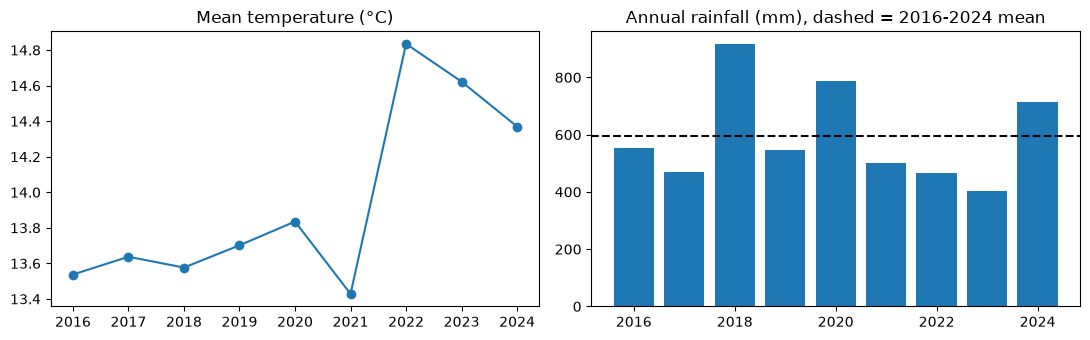

In [99]:
clim = ann.groupby("year")[["temp", "rain"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(clim.index, clim["temp"], marker="o"); ax[0].set(title="Mean temperature (°C)")
ax[1].bar(clim.index, clim["rain"]); ax[1].axhline(clim["rain"].mean(), color="k", ls="--")
ax[1].set(title="Annual rainfall (mm), dashed = 2016-2024 mean")
plt.tight_layout()

Text(0, 0.5, 'Area, 2016 = 100')

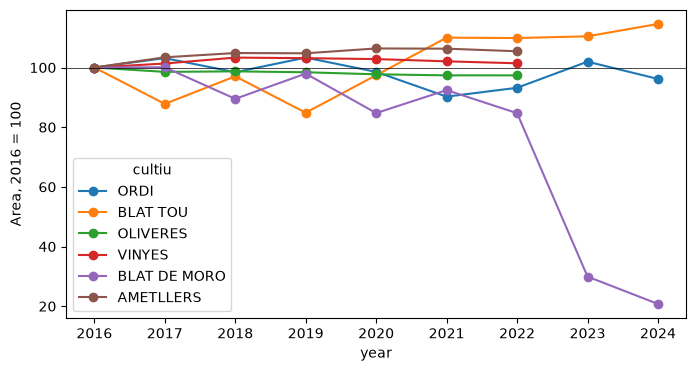

In [100]:
area = crops.groupby(["year", "cultiu"])["ha_total"].sum().unstack()
top = area.sum().nlargest(6).index
(area[top] / area[top].iloc[0] * 100).plot(figsize=(8, 4), marker="o")
plt.axhline(100, color="k", lw=.5); plt.ylabel("Area, 2016 = 100")

<Axes: xlabel='year', ylabel='Dryland share of area'>

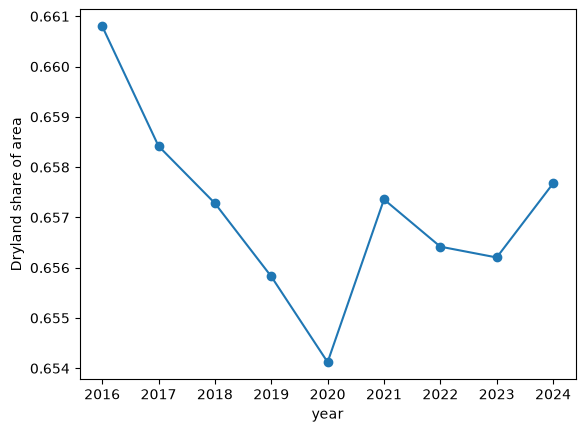

In [101]:
sr = crops.pivot_table(index="year", columns="seca_regadiu", values="ha_total", aggfunc="sum")
(sr["S"] / (sr["S"] + sr["R"])).plot(marker="o", ylabel="Dryland share of area")

[Text(0.5, 0, 'Temperature vs own average (°C)')]

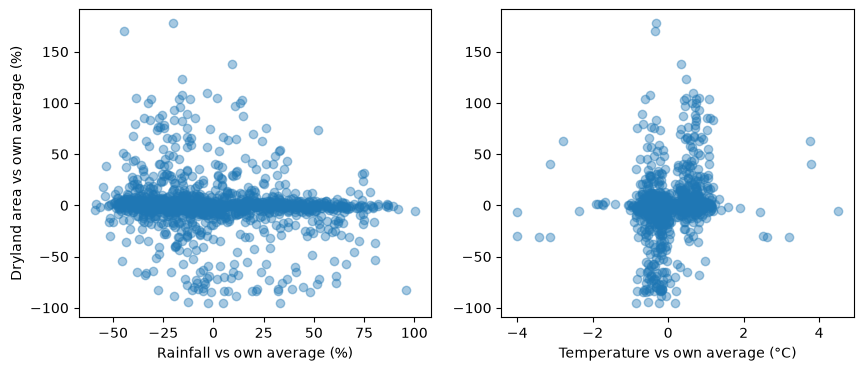

In [102]:
dry = (crops[crops["seca_regadiu"] == "S"]
       .groupby(["key", "year"])["ha_total"].sum().reset_index())
m = dry.merge(ann[["key", "year", "rain", "temp"]], on=["key", "year"])

for c in ["ha_total", "rain", "temp"]:
    m[c + "_anom"] = m.groupby("key")[c].transform(lambda s: s / s.mean() - 1 if c != "temp" else s - s.mean())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(m["rain_anom"] * 100, m["ha_total_anom"] * 100, alpha=.4)
ax[0].set(xlabel="Rainfall vs own average (%)", ylabel="Dryland area vs own average (%)")
ax[1].scatter(m["temp_anom"], m["ha_total_anom"] * 100, alpha=.4)
ax[1].set(xlabel="Temperature vs own average (°C)")

# Test 2

In [104]:
import requests, pandas as pd

BASE = "https://analisi.transparenciacatalunya.cat/resource/"
DAILY = BASE + "7bvh-jvq2.json"

def fetch_all(url, params, limit=50000):
    frames, offset = [], 0
    while True:
        r = requests.get(url, params={**params, "$limit": limit, "$offset": offset}, timeout=300)
        r.raise_for_status()
        rows = r.json()
        if rows:
            frames.append(pd.DataFrame(rows))
        if len(rows) < limit:
            break
        offset += limit
    return pd.concat(frames, ignore_index=True)

monthly = fetch_all(DAILY, {
    "$select": ("codi_estacio, date_extract_y(data_lectura) as yr, date_extract_m(data_lectura) as mo, "
                "nom_variable, avg(valor) as v_avg, sum(valor) as v_sum, count(valor) as n"),
    "$where": ("nom_variable in('Temperatura mitjana diària','Precipitació acumulada diària') "
               "AND data_lectura >= '1990-01-01T00:00:00'"),
    "$group": "codi_estacio, yr, mo, nom_variable",
    "$order": "codi_estacio, yr, mo, nom_variable",
})
for c in ["yr", "mo", "v_avg", "v_sum", "n"]:
    monthly[c] = pd.to_numeric(monthly[c])

In [117]:
CROPS_2015 = BASE + "3svg-ktn6.json"

params = {
    "$select": "campanya, municipi, cultiu, seca_regad, sum(ha) as ha_total",
    "$group": "campanya, municipi, cultiu, seca_regad",
    "$order": "campanya, municipi, cultiu, seca_regad",
}
c15 = fetch_all(CROPS_2015, params).rename(columns={"seca_regad": "seca_regadiu"})
c15["ha_total"] = c15["ha_total"].astype(float)

crops_all = pd.concat([c15, crops], ignore_index=True)
crops_all["campanya"] = crops_all["campanya"].astype(int)
crops_all["year"] = crops_all["campanya"]
crops_all["key"] = crops_all["municipi"].map(norm)

In [118]:
ok = monthly["n"] >= 25                       # month with at least 25 days of data
t = monthly[ok & monthly["nom_variable"].str.startswith("Temp")].rename(columns={"v_avg": "temp"})
r = monthly[ok & monthly["nom_variable"].str.startswith("Precip")].rename(columns={"v_sum": "rain"})

at = t.groupby(["codi_estacio", "yr"]).agg(temp=("temp", "mean"), m=("mo", "nunique")).query("m == 12")
ar = r.groupby(["codi_estacio", "yr"]).agg(rain=("rain", "sum"),  m=("mo", "nunique")).query("m == 12")
ann = at[["temp"]].join(ar[["rain"]], how="inner").reset_index()

# keep stations with at least 15 complete years inside 1991-2020
n_base = ann[ann["yr"].between(1991, 2020)].groupby("codi_estacio")["yr"].nunique()
ann = ann[ann["codi_estacio"].isin(n_base[n_base >= 15].index)]
print(ann["codi_estacio"].nunique(), "stations kept")

121 stations kept


In [119]:
norm_ = ann[ann["yr"].between(1991, 2020)].groupby("codi_estacio")[["temp", "rain"]].mean()
ann = ann.join(norm_, on="codi_estacio", rsuffix="_norm")
ann["dT"] = ann["temp"] - ann["temp_norm"]
ann["dR"] = (ann["rain"] / ann["rain_norm"] - 1) * 100
clim = ann.groupby("yr")[["dT", "dR"]].mean()

/var/folders/g3/w980056x1mj8f8wnrwl0qldr0000gn/T/ipykernel_47200/1114865428.py:2: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  ann = ann.join(norm_, on="codi_estacio", rsuffix="_norm")


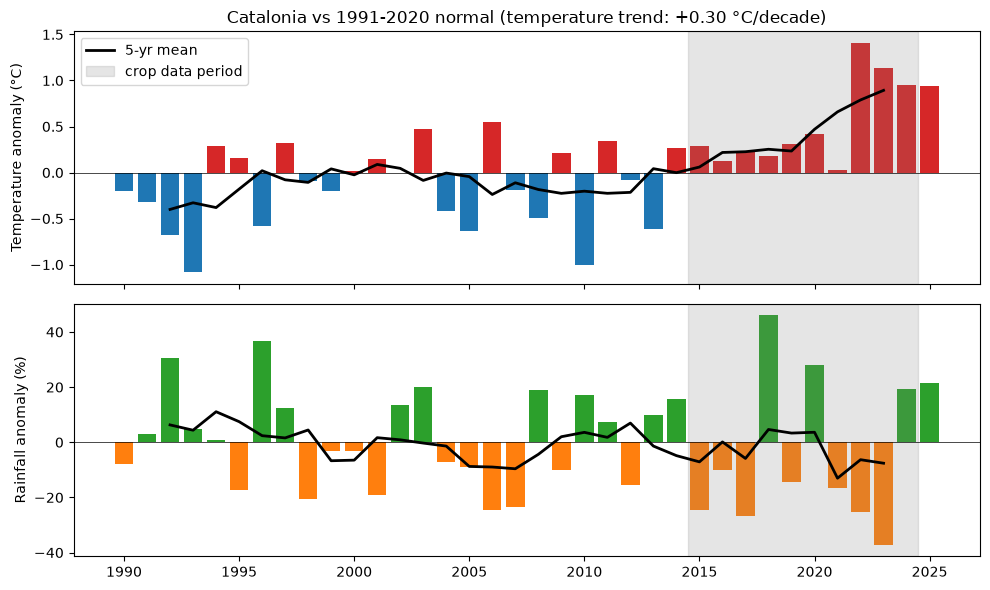

In [122]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for a, col, lab in [(ax[0], "dT", "Temperature anomaly (°C)"), (ax[1], "dR", "Rainfall anomaly (%)")]:
    a.bar(clim.index, clim[col], color=np.where(clim[col] > 0, "tab:red" if col == "dT" else "tab:green",
                                                              "tab:blue" if col == "dT" else "tab:orange"))
    a.plot(clim.index, clim[col].rolling(5, center=True).mean(), "k", lw=2, label="5-yr mean")
    a.axvspan(2014.5, 2024.5, color="grey", alpha=.2, label="crop data period")
    a.axhline(0, color="k", lw=.5); a.set_ylabel(lab)
ax[0].legend()
slope = np.polyfit(clim.index, clim["dT"], 1)[0] * 10
ax[0].set_title(f"Catalonia vs 1991-2020 normal (temperature trend: {slope:+.2f} °C/decade)")
plt.tight_layout()

/var/folders/g3/w980056x1mj8f8wnrwl0qldr0000gn/T/ipykernel_47200/1402479376.py:7: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  s = s.join(base_s, on="codi_estacio", rsuffix="_norm")


[Text(0.5, 0, 'Summer temperature anomaly (°C)')]

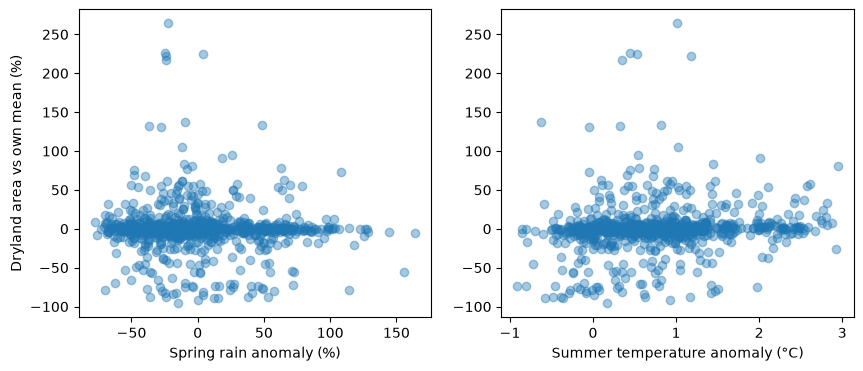

In [123]:
sp = (r[r["mo"].between(3, 6)].groupby(["codi_estacio", "yr"])["rain"].sum().rename("rain_spring").reset_index())
su = (t[t["mo"].between(6, 8)].groupby(["codi_estacio", "yr"])["temp"].mean().rename("temp_summer").reset_index())
s = sp.merge(su, on=["codi_estacio", "yr"])
s = s[s["codi_estacio"].isin(ann["codi_estacio"].unique())]

base_s = s[s["yr"].between(1991, 2020)].groupby("codi_estacio")[["rain_spring", "temp_summer"]].mean()
s = s.join(base_s, on="codi_estacio", rsuffix="_norm")
s["dR_spring"] = (s["rain_spring"] / s["rain_spring_norm"] - 1) * 100
s["dT_summer"] = s["temp_summer"] - s["temp_summer_norm"]

# station -> municipality, then merge with crops
smap = df_weather[["Codi_estacio", "Municipi"]].drop_duplicates()
smap["key"] = smap["Municipi"].map(norm)
s = s.merge(smap, left_on="codi_estacio", right_on="Codi_estacio")
s = s.groupby(["key", "yr"])[["dR_spring", "dT_summer"]].mean().reset_index()   # average stations per municipality

dry = (crops_all[crops_all["seca_regadiu"] == "S"].groupby(["key", "year"])["ha_total"].sum().reset_index()
       .rename(columns={"year": "yr"}))
m = dry.merge(s, on=["key", "yr"])
m["dA"] = m.groupby("key")["ha_total"].transform(lambda x: (x / x.mean() - 1) * 100)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(m["dR_spring"], m["dA"], alpha=.4); ax[0].set(xlabel="Spring rain anomaly (%)", ylabel="Dryland area vs own mean (%)")
ax[1].scatter(m["dT_summer"], m["dA"], alpha=.4); ax[1].set(xlabel="Summer temperature anomaly (°C)")

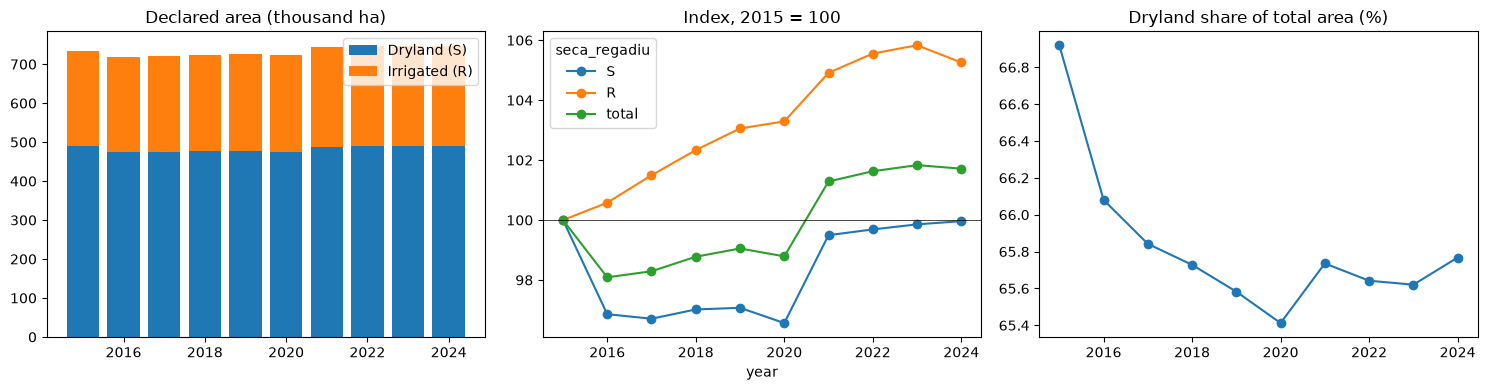

In [124]:
ha = crops_all.pivot_table(index="year", columns="seca_regadiu", values="ha_total", aggfunc="sum")
ha["total"] = ha["S"] + ha["R"]
ha["share_S"] = ha["S"] / ha["total"] * 100

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].bar(ha.index, ha["S"] / 1e3, label="Dryland (S)")
ax[0].bar(ha.index, ha["R"] / 1e3, bottom=ha["S"] / 1e3, label="Irrigated (R)")
ax[0].set(title="Declared area (thousand ha)"); ax[0].legend()

(ha[["S", "R", "total"]] / ha[["S", "R", "total"]].iloc[0] * 100).plot(ax=ax[1], marker="o")
ax[1].axhline(100, color="k", lw=.5); ax[1].set(title="Index, 2015 = 100", ylabel="")

ax[2].plot(ha.index, ha["share_S"], marker="o")
ax[2].set(title="Dryland share of total area (%)")
plt.tight_layout()

# Downloading of crop data

The data seen until now has crop data since 2016. This is not suficient to analyse climate trends but weather variations. Not suficient. So an alternative has been found (Excel files from 2008 to 2026). 

Since 2022, wine and oil production has changed format. It is assigned to the district (comarca) where the winery or olive mill is located and, as of 2023, to the district where the grapes or olives are harvested (Idescat 2023 methodological note). Yield figures by district for these two crops may be somewhat distorted prior to 2023, and the data series may show a break in methodology that year.

In [194]:
import idescat_loader
src = open(idescat_loader.__file__).read()
print(idescat_loader.__file__)
print(len(src.splitlines()), "lines;", "_load_new" in src)
importlib.reload(idescat_loader)

/Users/hsala/Documents/HS/University/Master/Massive data analysis and visualization/Code/XEMAS-/notebook/idescat_loader.py
245 lines; True


<module 'idescat_loader' from '/Users/hsala/Documents/HS/University/Master/Massive data analysis and visualization/Code/XEMAS-/notebook/idescat_loader.py'>

In [195]:
df_crops = load_all("../data/Crop_data")
df_crops.head()

Loading: ['Produccions_comarcals_2013.xls', 'Produccions_comarcals_2014.xlsx', 'Produccions_comarcals_2015.xlsx', 'Produccions_comarcals_2016.xlsx', 'Produccions_comarcals_2017.xlsx', 'Produccions_comarcals_2018.xlsx', 'Produccions_comarcals_2019.xlsx', 'Produccions_comarcals_2020.xlsx', 'Produccions_comarcals_2021.xlsx', 'Produccions_comarcals_2022.xlsx', 'Produccions_comarcals_2023.xlsx', 'Produccions_comarcals_2024.xlsx', 'Produccions_comarcals_2025.xlsx', 'produccions_comarcals_2008.xls', 'produccions_comarcals_2009.xls', 'produccions_comarcals_2010.xls', 'produccions_comarcals_2011.xls', 'produccions_comarcals_2012.xls']


,comarca,group,crop,area_dry_ha,area_irr_open_ha,area_irr_protected_ha,yield_dry_kg_ha,yield_irr_open_kg_ha,yield_irr_protected_kg_ha,production_t,...,yield_irr_kg_ha,area_irr_total_ha,area_total_ha,yield_total_kg_ha,yield_prod_kg_ha,comarca_code,crop_code,trees_n,yield_trees_kg_tree,group_code
0,Alt Camp,FLORS I PLANTES ORNAMENTALS,Clavell,0.0,0.0000,0.0000,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
1,Alt Camp,FLORS I PLANTES ORNAMENTALS,Rosa,0.0,0.0000,0.0000,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
2,Alt Camp,FLORS I PLANTES ORNAMENTALS,Altres flors,0.0,0.0000,0.0000,NaN,NaN,NaN,NaN,...,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,<NA>
3,Alt Camp,FLORS I PLANTES ORNAMENTALS,Plantes ornamentals,0.0,1.2992,0.1008,NaN,NaN,NaN,NaN,...,NaN,1.4,1.4,0.0,NaN,NaN,NaN,NaN,NaN,<NA>
4,Alt Camp,HORTALISSES,Col de cabdell,0.0,1.8000,0.0000,NaN,25000.0,NaN,45.0,...,NaN,1.8,1.8,25000.0,25000.0,NaN,NaN,NaN,NaN,<NA>


In [196]:
import importlib, idescat_loader; importlib.reload(idescat_loader)
from idescat_loader import load_all, harmonise
df = load_all("../data/Crop_data")
h  = harmonise(df)          # year, comarca, crop_h, áreas, producción, yield_prod_kg_ha
h = h[~h.comarca.isin(["Moianès", "Lluçanès"])]
h.head(10)

Loading: ['Produccions_comarcals_2013.xls', 'Produccions_comarcals_2014.xlsx', 'Produccions_comarcals_2015.xlsx', 'Produccions_comarcals_2016.xlsx', 'Produccions_comarcals_2017.xlsx', 'Produccions_comarcals_2018.xlsx', 'Produccions_comarcals_2019.xlsx', 'Produccions_comarcals_2020.xlsx', 'Produccions_comarcals_2021.xlsx', 'Produccions_comarcals_2022.xlsx', 'Produccions_comarcals_2023.xlsx', 'Produccions_comarcals_2024.xlsx', 'Produccions_comarcals_2025.xlsx', 'produccions_comarcals_2008.xls', 'produccions_comarcals_2009.xls', 'produccions_comarcals_2010.xls', 'produccions_comarcals_2011.xls', 'produccions_comarcals_2012.xls']


,year,comarca,crop_h,area_dry_ha,area_irr_total_ha,area_total_ha,production_t,yield_prod_kg_ha
0,2008,Alt Camp,Albercoquer,0.0,2.0,2.0,12.334,6167.000000
1,2008,Alt Camp,Albergínia,0.0,12.0,12.0,324.000,27000.000000
2,2008,Alt Camp,Alfals,1.0,3.0,4.0,57.000,14250.000000
3,2008,Alt Camp,All,1.0,1.0,2.0,17.000,8500.000000
4,2008,Alt Camp,Altres Hortalisses,1.0,7.0,8.0,74.000,9250.000000
5,2008,Alt Camp,Altres conreus industrials,0.0,2.0,2.0,5.000,2500.000000
6,2008,Alt Camp,Altres lleguminoses,10.0,0.0,10.0,15.000,1500.000000
7,2008,Alt Camp,Ametller,2729.0,105.0,2834.0,1677.320,591.856034
8,2008,Alt Camp,Avellaner,325.0,2275.0,2600.0,6929.000,2665.000000
9,2008,Alt Camp,Blat,202.0,4.0,206.0,836.000,4058.252427


# Downloading of climate data and relation with crops

### Preparing the variables
First of all we have to compute the yield, y, per year (in kg, therefore multiply by 1000 production (in tones)). To do so we divide the production, P, of the crop of year t, by the total area, A, of the different variants of crops we have (for example the different types of wheat)
$$y_{crop, t}=\frac{1000 P_{crop, t}}{\sum_{variants}A_{crop, t, variant}}.$$
About weather data, we do the mean for the whole mont of rain accumulated per day and mean temperature per day. We will consider only months with 25 days of data.

### Crop trend deviation
$$\ln y_{crop, t}=a_{crop} + b_{crop}*t + d_{crop, t}$$
The basic straight line $a_{crop} + b_{crop}*t$ is the tendency of the crops' yield to improve due technique and technology improvement, and $d_{crop, t}$ is the relative deviation (due to logarithm) from the trend, which we associate to yield anomaly due to weather.
Ex. if the trend predicts 3500 kg/ha of wheat and the real yield was 2800, then $d = \ln(2800/3500) = -0.22$, about 20 % below trend.

### Weather trend deviation
We take the data of all the years for a single station and average the monthly data (we will take stations with at least 10 years). The anomaly is computed taking the month averaged value over years, minus the station value of that specific month. We average over all stations in the comarca, $\Delta T_{crop, t}$.
Also, we are focusing on seasonal windows per crop (october to june for wheat or barley, february to september for olive)(in fact we have classified this into cereals, growing and tree).
For the rain, the deviation from the mean, as a percentage of the normal rain per season:
$$\Delta R_{crop, t}=\frac{\sum_{month} \Delta R_{month}}{\sum_{month} \Delta <R_{month}>}$$
where $\Delta R$ is the rain anomaly (as percentage of the mean) computed as mentinoned a few lines above.

### Computation of the deviation due climate
From the weather deviations, we build the regression:
$$d_{crop, t} = offset + \beta_T \Delta T_{crop, t} + \beta_R \Delta R_{crop, t}$$
where $\beta_T \times 100$ is the yield change as a percentage per +1ºC and $\beta_P \times 100$ is the yield change per +100% rainfall. Ex. With $\beta_P = 0.46$, a season 10 % wetter than normal gives about 4.6 % more yield.

In [ ]:

import climate_yield as C
from idescat_loader import load_all, harmonise, fix_comarca

daily = C.download_daily(2007, 2025)
stations = C.download_stations()
mst = C.monthly_station(daily)
cm  = C.comarca_monthly(mst, stations, fix_comarca)

h  = harmonise(load_all("../data/Crop_data"))
h  = h[~h.comarca.isin(["Moianès", "Lluçanès"])]
ya = C.yield_anomaly(h)
tab, data = C.fit(ya, cm)
print(tab.round(3))

2007 115127
2008 118068
2009 121071
2010 123036
2011 123878
2012 125576
2013 126517
2014 127605
2015 129789
2016 132301
2017 132620
2018 134923
2019 135702
2020 136007
2021 135971
2022 135313
2023 134929
2024 135340
2025 134844
Loading: ['Produccions_comarcals_2013.xls', 'Produccions_comarcals_2014.xlsx', 'Produccions_comarcals_2015.xlsx', 'Produccions_comarcals_2016.xlsx', 'Produccions_comarcals_2017.xlsx', 'Produccions_comarcals_2018.xlsx', 'Produccions_comarcals_2019.xlsx', 'Produccions_comarcals_2020.xlsx', 'Produccions_comarcals_2021.xlsx', 'Produccions_comarcals_2022.xlsx', 'Produccions_comarcals_2023.xlsx', 'Produccions_comarcals_2024.xlsx', 'Produccions_comarcals_2025.xlsx', 'produccions_comarcals_2008.xls', 'produccions_comarcals_2009.xls', 'produccions_comarcals_2010.xls', 'produccions_comarcals_2011.xls', 'produccions_comarcals_2012.xls']
                     crop   window    n  n_comarques  b_T_pct_per_C    p_T  \
0                    Blat   cereal  450           25        

In [208]:
import numpy as np, pandas as pd, statsmodels.formula.api as smf

def two_way(d):
    g = np.column_stack([pd.factorize(d["comarca"])[0], d["year"].to_numpy()])
    return smf.ols("e ~ dT + dP_rel", d).fit(cov_type="cluster", cov_kwds={"groups": g})

for crop in ["Blat", "Ordi", "Blat de moro", "Olivera", "Vinya de raïm per a vi"]:
    d = data[data.crop_h == crop]
    r = two_way(d)                                    # cluster by comarca AND year
    loo = [smf.ols("e ~ dT + dP_rel", d[d.year != y]).fit().params["dT"] * 100
           for y in sorted(d.year.unique())]          # drop one year at a time
    print(crop, "b_T %.1f (p=%.3f)" % (100 * r.params["dT"], r.pvalues["dT"]),
          "| leave-one-year-out range: %.1f to %.1f" % (min(loo), max(loo)),
          "| corr(dT,dP): %.2f" % d[["dT", "dP_rel"]].corr().iloc[0, 1])

Blat b_T -9.4 (p=0.288) | leave-one-year-out range: -15.3 to -2.4 | corr(dT,dP): -0.22
Ordi b_T -8.3 (p=0.461) | leave-one-year-out range: -16.2 to 0.6 | corr(dT,dP): -0.22
Blat de moro b_T -3.2 (p=0.414) | leave-one-year-out range: -6.1 to -0.6 | corr(dT,dP): -0.36
Olivera b_T -10.3 (p=0.432) | leave-one-year-out range: -19.0 to 3.7 | corr(dT,dP): -0.26
Vinya de raïm per a vi b_T -6.0 (p=0.118) | leave-one-year-out range: -8.6 to -4.2 | corr(dT,dP): -0.35


In [209]:
d = data[data.crop_h == "Blat"]
r = two_way(d)
print(r.summary().tables[1])                       # b_T y b_P con sus p-valores

# which year moves b_T the most
full = r.params["dT"] * 100
infl = {y: full - 100 * smf.ols("e ~ dT + dP_rel", d[d.year != y]).fit().params["dT"]
        for y in sorted(d.year.unique())}
print(pd.Series(infl).round(1).sort_values())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0046      0.052     -0.089      0.929      -0.106       0.097
dT            -0.0942      0.089     -1.063      0.288      -0.268       0.079
dP_rel         0.4610      0.180      2.560      0.010       0.108       0.814
2023   -7.1
2021   -2.2
2024   -0.9
2013   -0.7
2016   -0.5
2011   -0.5
2018   -0.5
2015   -0.4
2017   -0.1
2020    0.0
2014    0.1
2009    0.2
2019    0.2
2010    0.3
2012    0.3
2022    0.5
2008    5.6
2025    5.9
dtype: float64


### What data do we have until now?
- Crops: for every comarca and crop from 2008 to 2025 we have hectares (dryland and irrigated), yield and production. They come from the 18 Idescat excel files.
- Climate: daily mean temperature and rainfall from the XEMA weather stations, 2007 to 2025, grouped by comarca.
We had to clean some of the data in those dataframes. There were misspellings and abbreviations in Comarques names. Wheat, Barley, olive and almonds and hazelnuts had to be unified as names changed in different years datasets. Moianés and Lluçanés were dropped off as are comarques recently splited off from others.

### The treatment we did:
- In order to just account for meteorological effects, we measured how far each year's field was from its own trend (we suspect that part of the increase of yield could be associated to machinery, better seeds and technique improvements). Therefore, the desviation from the trend leaves us only good and bad years due to weather.
- For each comarca and year we measured how far the temperature and rainfall during the crop’s growing cycle where from it's typical value. And we compared these deviations with the good and bad years of crops.

### Problems we may have:
- 18 years are not much to hold a statement related to climate, rather than weather.
- In wine and oil production, the yield changed location, from 2023 on, saving into the dataset the milling location instead of the plantation one.
- In 2023 there's a drop in olive, maize and almond. In 2023 there was an emergency of draught so that could explain it, but we can't be sure.
- In 2007 (out of the measures), there was a severe drought. In 2008, the rain accumulated concentrated only in june-july and harmed a lot the crops, which were as well affected by the severe drought. This explains why the crop yields were really poor with high accumulation of precipitation.


# Plots

### Time series plot
Upper plot: the rain anomaly $\Delta R$ averaged for all comarques, per year.\
Lower plot: the yield anomaly due to the weather $d_{crop, t}$ averaged for all comarques, per year.

### Scatter plot
X axis: rain anomaly $\Delta R$ for every comarques in one year.\
Y axis: yield anomaly due to the weather $d_{crop, t}$ for every comarques in one year.\
Therefore, each point is a comarca during a year. We colored 2015, 2020 and 2023 as are years with draught (15 and 23) and rainy.\
The straight line is a regression to see if there's correlation, considering only rain annomaly (didn't considered temperature as it doesn't affect as much) (this is done through OLS)
$$d_{crop, t} = offset + \beta_R \Delta R_{crop, t}$$

### Maps
Upper plot: the rain anomaly $\Delta R$ per comarca.\
Lower plot: the yield anomaly due to the weather $d_{crop, t}$ per comarca.



We have found interesting to plot this for different type of crops, known to be more or less watter resistant (dryland crops are affected by lack of rain, olive is one of the mostr draught resistant)

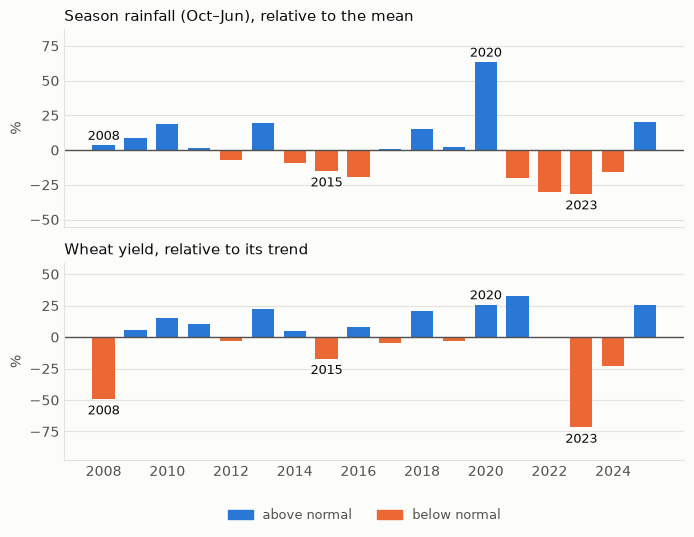

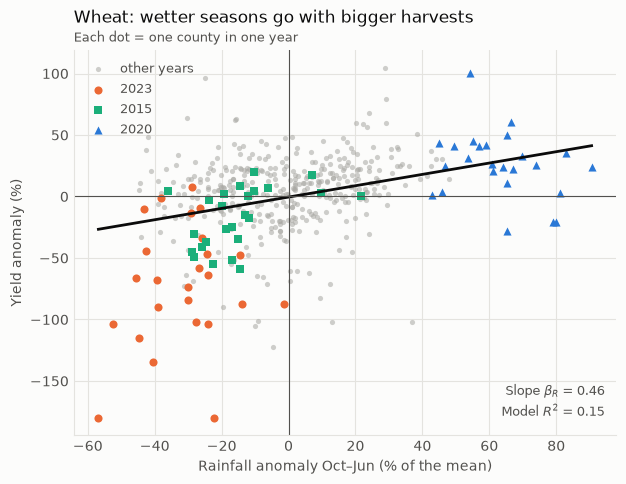

name column: NOMCOMAR | matches: 41


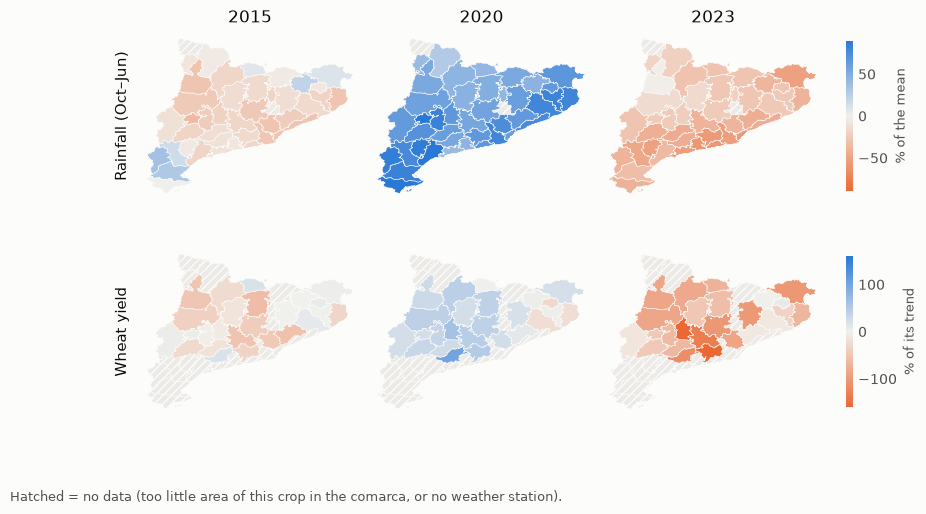

In [236]:
import importlib, plots as P
importlib.reload(P)

P.fig_time(data, "Blat")
P.fig_scatter(data, "Blat", highlight=(2023, 2015, 2020))
geo = P.load_comarques("../data/divisions-administratives-v2r1-comarques-250000-20250730.json",fix_comarca, known=set(h.comarca))
P.fig_maps(geo, data, cm, years=(2015, 2020, 2023), crop="Blat")

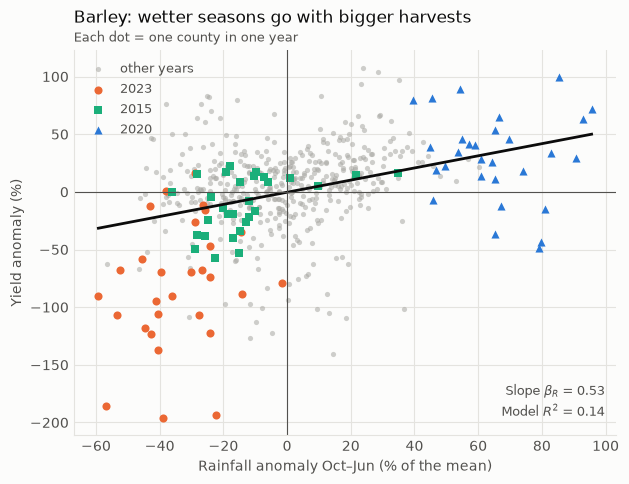

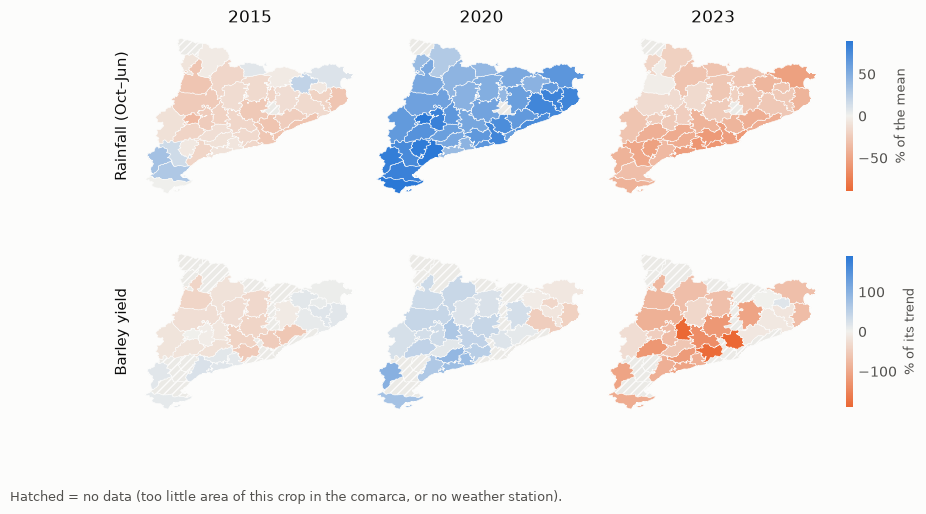

In [239]:
P.fig_scatter(data, "Ordi",highlight=(2023, 2015, 2020))
P.fig_maps(geo, data, cm, years=(2015, 2020, 2023), crop="Ordi")


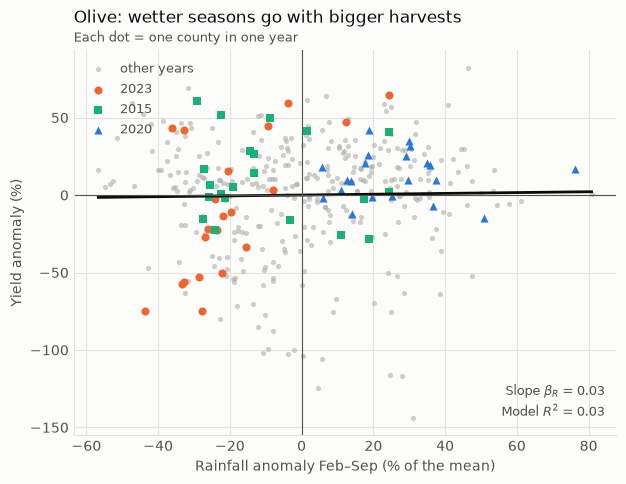

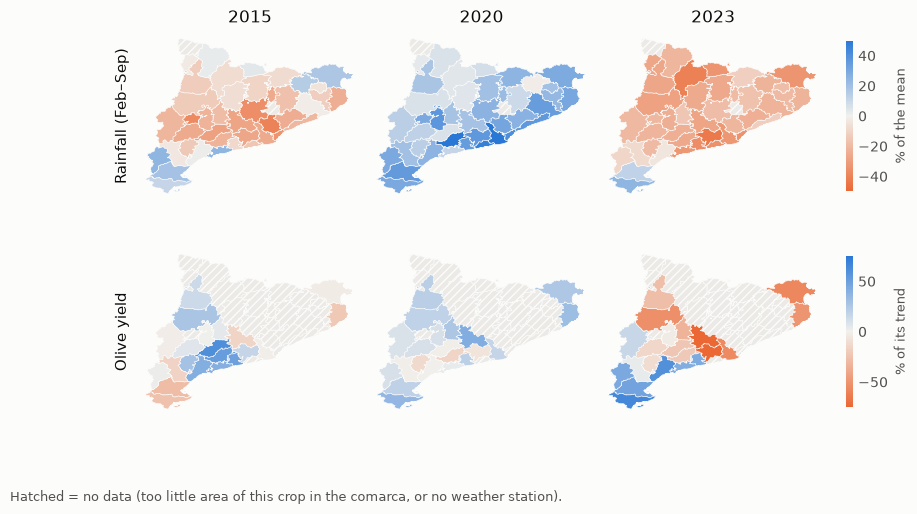

In [238]:
P.fig_scatter(data, "Olivera",highlight=(2023, 2015, 2020))
P.fig_maps(geo, data, cm, years=(2015, 2020, 2023), crop="Olivera")